In [1]:
import numpy as np
import plotly.graph_objects as go
from ipywidgets import interact
from tqdm.notebook import tqdm  # for progress bar
import time
import os

# Simple 5-point Laplacian for 2D array
def laplacian(Z):
    return (
        -4 * Z
        + np.roll(Z, (0, -1), (0, 1))
        + np.roll(Z, (0, 1), (0, 1))
        + np.roll(Z, (-1, 0), (0, 1))
        + np.roll(Z, (1, 0), (0, 1))
    )

def gray_scott_step(u, v, Du, Dv, F, k, dt):
    Lu, Lv = laplacian(u), laplacian(v)
    uvv = u * v * v
    u += dt * (Du * Lu - uvv + F * (1 - u))
    v += dt * (Dv * Lv + uvv - (F + k) * v)
    # keep values physical
    np.clip(u, 0, 1, out=u)
    np.clip(v, 0, 1, out=v)
    return u, v


In [2]:
import plotly.graph_objects as go
from ipywidgets import FloatSlider, VBox, HBox

def create_interactive_pattern_plot(pattern, Du_values, Dv_values, model_name="Model"):
    """
    Create an interactive Plotly FigureWidget to explore a 2D pattern
    interpolated over (Du, Dv) parameter space.

    Parameters
    ----------
    interp_func : RegularGridInterpolator
        The interpolation function returning a 2D pattern for (Du, Dv).
    Du_values, Dv_values : np.ndarray
        Arrays defining the parameter grid.
    model_name : str
        Name of the model to display in the figure title.
    """
    # --- Build interpolator across (Du, Dv) parameter space ---
    # axes correspond to the first two dimensions of patterns
    interp_func = RegularGridInterpolator(
        (Du_values, Dv_values),
        pattern,
        bounds_error=False,
        fill_value=None)
    # --- Initialize sliders ---
    Du_slider = FloatSlider(
        min=Du_values.min(), max=Du_values.max(),
        step=0.002, value=Du_values[0], description='Du'
    )
    Dv_slider = FloatSlider(
        min=Dv_values.min(), max=Dv_values.max(),
        step=0.002, value=Dv_values[0], description='Dv'
    )

    # --- Initial field ---
    u_field = interp_func((Du_slider.value, Dv_slider.value))
    fig = go.FigureWidget(
        data=[go.Heatmap(z=u_field, colorscale='Viridis', zmin=0, zmax=1,
                         colorbar=dict(title='u concentration'))],
        layout=go.Layout(
            title=f"{model_name} pattern | Du={Du_slider.value:.3f}, Dv={Dv_slider.value:.3f}",
            width=600, height=600,
            margin=dict(l=20, r=20, t=40, b=20)
        )
    )

    # --- Callback for smooth updates ---
    def update_plot(change=None):
        u_field = interp_func((Du_slider.value, Dv_slider.value))
        with fig.batch_update():
            fig.data[0].z = u_field
            fig.layout.title = f"{model_name} pattern | Du={Du_slider.value:.3f}, Dv={Dv_slider.value:.3f}"

    # --- Attach slider observers ---
    Du_slider.observe(update_plot, names='value')
    Dv_slider.observe(update_plot, names='value')

    return VBox([fig, HBox([Du_slider, Dv_slider])])


In [3]:

# Simulation grid parameters
nx, ny = 128, 128
nDu, nDv = 16, 16  # parameter grid resolution

Du_values = np.linspace(0.1, 0.20, nDu)
Dv_values = np.linspace(0.001, 0.06, nDv)

F, k, dt = 0.035, 0.060, 1.0
nsteps = 2000  # fewer iterations for faster build

patterns = np.empty((nDu, nDv, ny, nx), dtype=np.float32)

start_time = time.time()
tol = 1e-6        # convergence tolerance
check_interval = 20  # check every N steps to avoid extra overhead


# Outer loops wrapped with tqdm
for i, Du in enumerate(tqdm(Du_values, desc="Diffusion Du", position=0)):
    for j, Dv in enumerate(tqdm(Dv_values, desc=f"Dv loop", position=1, leave=False)):
        u, v = np.ones((ny, nx)), np.zeros((ny, nx))
        r = 10
        u[ny//2-r:ny//2+r, nx//2-r:nx//2+r] = 0.50
        v[ny//2-r:ny//2+r, nx//2-r:nx//2+r] = 0.25
        for n in range(nsteps):
            u_prev, v_prev = u.copy(), v.copy()
            u, v = gray_scott_step(u, v, Du, Dv, F, k, dt)
        
            if n % check_interval == 0:
                du = np.max(np.abs(u - u_prev))
                dv = np.max(np.abs(v - v_prev))
                if max(du, dv) < tol:
                    #print(f"Steady state reached after {n} steps (Δu={du:.2e}, Δv={dv:.2e})")
                    steady_reached = True
                    break
        if not steady_reached:
            print(f"Did not converge after {nsteps} steps (last Δu={du:.2e}, Δv={dv:.2e})")
        u_norm = (u - u.min()) / (u.max() - u.min() + 1e-9)
        patterns[i, j] = u_norm

elapsed = time.time() - start_time
print(f"✅ Cache built in {elapsed:.1f} s | size ≈ {patterns.nbytes/1e6:.1f} MB")

# Save results locally as compressed NPZ
np.savez_compressed("reaction_diffusion_cache.npz",
                    patterns=patterns,
                    Du_values=Du_values,
                    Dv_values=Dv_values)

print("💾 Saved cache to 'reaction_diffusion_cache.npz'")


Diffusion Du:   0%|          | 0/16 [00:00<?, ?it/s]

Dv loop:   0%|          | 0/16 [00:00<?, ?it/s]

Dv loop:   0%|          | 0/16 [00:00<?, ?it/s]

Dv loop:   0%|          | 0/16 [00:00<?, ?it/s]

Dv loop:   0%|          | 0/16 [00:00<?, ?it/s]

...

Dv loop:   0%|          | 0/16 [00:00<?, ?it/s]

Dv loop:   0%|          | 0/16 [00:00<?, ?it/s]

Dv loop:   0%|          | 0/16 [00:00<?, ?it/s]

Dv loop:   0%|          | 0/16 [00:00<?, ?it/s]

✅ Cache built in 87.2 s | size ≈ 16.8 MB
💾 Saved cache to 'reaction_diffusion_cache.npz'


In [4]:
import os
import numpy as np
import plotly.graph_objects as go
from ipywidgets import FloatSlider, VBox, HBox
from scipy.interpolate import RegularGridInterpolator

# Load cached data if not already loaded
if "patterns" not in globals():
    if os.path.exists("reaction_diffusion_cache.npz"):
        print("💾 Loading cached data from 'reaction_diffusion_cache.npz' ...")
        data = np.load("reaction_diffusion_cache.npz")
        patterns = data["patterns"]
        Du_values = data["Du_values"]
        Dv_values = data["Dv_values"]
        print(f"✅ Loaded cache: shape {patterns.shape}")
    else:
        raise FileNotFoundError("No cache found — please run the precomputation cell first.")

create_interactive_pattern_plot(patterns, Du_values, Dv_values, "Gray-Scott pattern")

    'data': [{'colorbar': {'title': {'text': 'u concentration'}},
              …

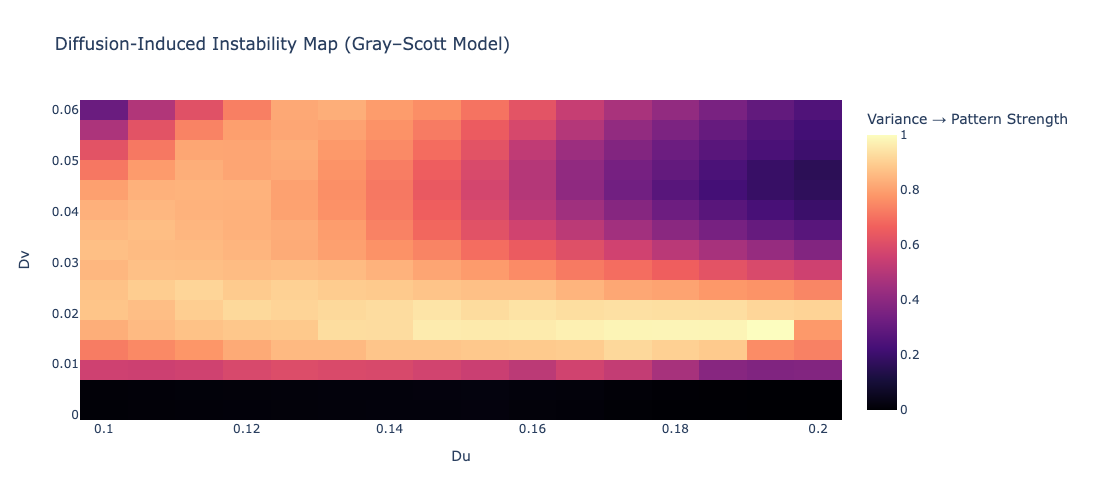

In [5]:
import numpy as np
import plotly.express as px

# --- Compute spatial variance for each (Du, Dv) ---
# patterns: shape (nDu, nDv, ny, nx)
variance_map = np.var(patterns, axis=(2, 3))   # collapse spatial dims

# Normalize to [0,1] for consistent color scaling
variance_norm = (variance_map - variance_map.min()) / (variance_map.max() - variance_map.min() + 1e-9)

# --- Create Plotly heatmap of instability regions ---
fig = px.imshow(
    variance_norm.T,                 # transpose so Du = x-axis, Dv = y-axis
    x=Du_values,
    y=Dv_values,
    color_continuous_scale="Magma",
    origin="lower",
    aspect="auto",
    labels=dict(x="Du", y="Dv", color="Pattern Variance"),
    title="Diffusion-Induced Instability Map (Gray–Scott Model)"
)
fig.update_layout(width=600, height=500, coloraxis_colorbar=dict(title="Variance → Pattern Strength"))
fig.show()


In [6]:

# === Schnakenberg model parameters ===
a, b = 0.1, 0.9       # reaction parameters (choose 0 < a < b for interesting Turing regimes)
dt = 0.1              # stable explicit time step
nsteps = 1500         # time iterations per simulation

# === Spatial grid ===
nx, ny = 128, 128
nDu, nDv = 16, 16     # parameter grid resolution

Du_values_sch = np.linspace(0.05, 0.30, nDu)
Dv_values_sch = np.linspace(0.05, 0.65, nDv)   # inhibitor diffuses faster

# === Define Laplacian and update step ===
def laplacian(Z):
    return (
        -4 * Z
        + np.roll(Z, 1, axis=0) + np.roll(Z, -1, axis=0)
        + np.roll(Z, 1, axis=1) + np.roll(Z, -1, axis=1)
    )

def schnakenberg_step(u, v, Du, Dv, a, b, dt):
    Lu, Lv = laplacian(u), laplacian(v)
    f = a - u + u*u*v
    g = b - u*u*v
    u += dt * (Du * Lu + f)
    v += dt * (Dv * Lv + g)
    # clip to physical range
    np.clip(u, 0, 100, out=u)
    np.clip(v, 0, 100, out=v)
    return u, v

# === Allocate cache ===
patterns_sch = np.empty((nDu, nDv, ny, nx), dtype=np.float32)

# === Compute ===
start_time = time.time()
tol = 1e-6        # convergence tolerance
check_interval = 20  # check every N steps to avoid extra overhead

for i, Du in enumerate(tqdm(Du_values_sch, desc="Diffusion Du", position=0)):
    for j, Dv in enumerate(tqdm(Dv_values_sch, desc="  Diffusion Dv", position=1, leave=False)):
        # initialize near steady state with random perturbation
        u = a + b + 0.01 * np.random.randn(ny, nx)
        v = b / (a + b)**2 + 0.01 * np.random.randn(ny, nx)
        steady_reached = False
            
        for n in range(nsteps):
            u_prev, v_prev = u.copy(), v.copy()
            u, v = schnakenberg_step(u, v, Du, Dv, a, b, dt)
        
            if n % check_interval == 0:
                du = np.max(np.abs(u - u_prev))
                dv = np.max(np.abs(v - v_prev))
                if max(du, dv) < tol:
                    #print(f"Steady state reached after {n} steps (Δu={du:.2e}, Δv={dv:.2e})")
                    steady_reached = True
                    break
        if not steady_reached:
            print(f"Did not converge after {nsteps} steps (last Δu={du:.2e}, Δv={dv:.2e})")


        # normalize u for visualization
        u_norm = (u - u.min()) / (u.max() - u.min() + 1e-9)
        patterns_sch[i, j] = u_norm

elapsed = time.time() - start_time
print(f"✅ Schnakenberg cache built in {elapsed:.1f}s | size ≈ {patterns_sch.nbytes/1e6:.1f} MB")

# === Save compressed ===
np.savez_compressed(
    "schnakenberg_cache.npz",
    patterns_sch=patterns_sch,
    Du_values_sch=Du_values_sch,
    Dv_values_sch=Dv_values_sch,
    a=a, b=b, dt=dt, nsteps=nsteps
)
print("💾 Saved Schnakenberg cache to 'schnakenberg_cache.npz'")


Diffusion Du:   0%|          | 0/16 [00:00<?, ?it/s]

  Diffusion Dv:   0%|          | 0/16 [00:00<?, ?it/s]

Did not converge after 1500 steps (last Δu=2.60e-06, Δv=1.23e-06)
Did not converge after 1500 steps (last Δu=2.14e-04, Δv=9.45e-05)
Did not converge after 1500 steps (last Δu=1.27e-03, Δv=7.05e-04)
Did not converge after 1500 steps (last Δu=2.93e-03, Δv=1.83e-03)
Did not converge after 1500 steps (last Δu=2.74e-03, Δv=1.56e-03)
Did not converge after 1500 steps (last Δu=3.12e-03, Δv=1.75e-03)
Did not converge after 1500 steps (last Δu=3.84e-03, Δv=1.96e-03)


  Diffusion Dv:   0%|          | 0/16 [00:00<?, ?it/s]

Did not converge after 1500 steps (last Δu=5.58e-06, Δv=2.63e-06)
Did not converge after 1500 steps (last Δu=4.83e-04, Δv=2.03e-04)
Did not converge after 1500 steps (last Δu=1.25e-03, Δv=6.23e-04)


...

  Diffusion Dv:   0%|          | 0/16 [00:00<?, ?it/s]

  Diffusion Dv:   0%|          | 0/16 [00:00<?, ?it/s]

  Diffusion Dv:   0%|          | 0/16 [00:00<?, ?it/s]

  Diffusion Dv:   0%|          | 0/16 [00:00<?, ?it/s]

✅ Schnakenberg cache built in 58.0s | size ≈ 16.8 MB
💾 Saved Schnakenberg cache to 'schnakenberg_cache.npz'


In [8]:
import os
import numpy as np
import plotly.graph_objects as go
from ipywidgets import interact, FloatSlider
from scipy.interpolate import RegularGridInterpolator

# Load cached data if not already loaded
if "patterns_sch" not in globals():
    if os.path.exists("schnakenberg_cache.npz"):
        print("💾 Loading cached data from 'schnakenberg_cache.npz' ...")
        data_sch = np.load("schnakenberg_cache.npz")
        patterns_sch = data_sch["patterns_sch"]
        Du_values_sch = data_sch["Du_values_sch"]
        Dv_values_sch = data_sch["Dv_values_sch"]
        print(f"✅ Loaded cache: shape {patterns_sch.shape}")
    else:
        raise FileNotFoundError("No cache found — please run the precomputation cell first.")

create_interactive_pattern_plot(patterns_sch, Du_values_sch, Dv_values_sch, "Schnakenberg pattern")


    'data': [{'colorbar': {'title': {'text': 'u concentration'}},
              …

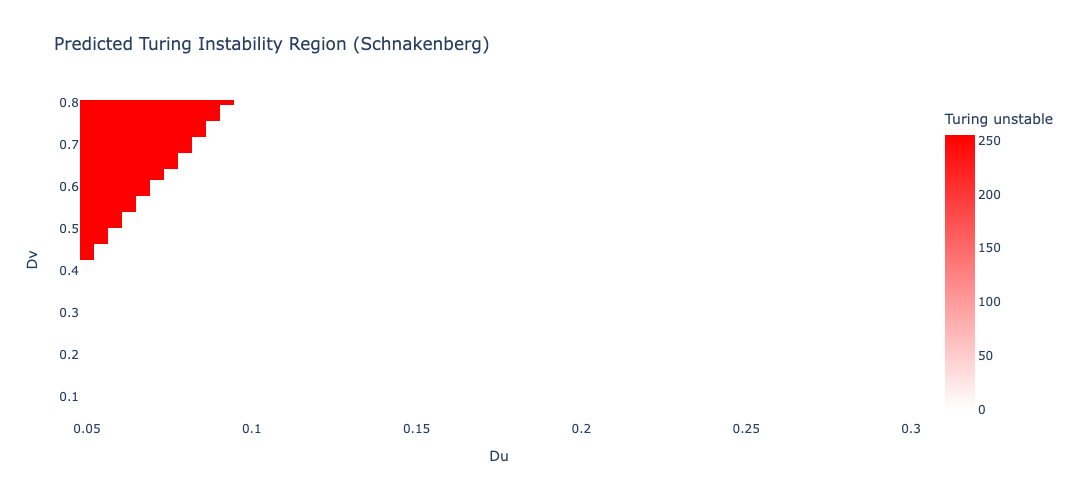

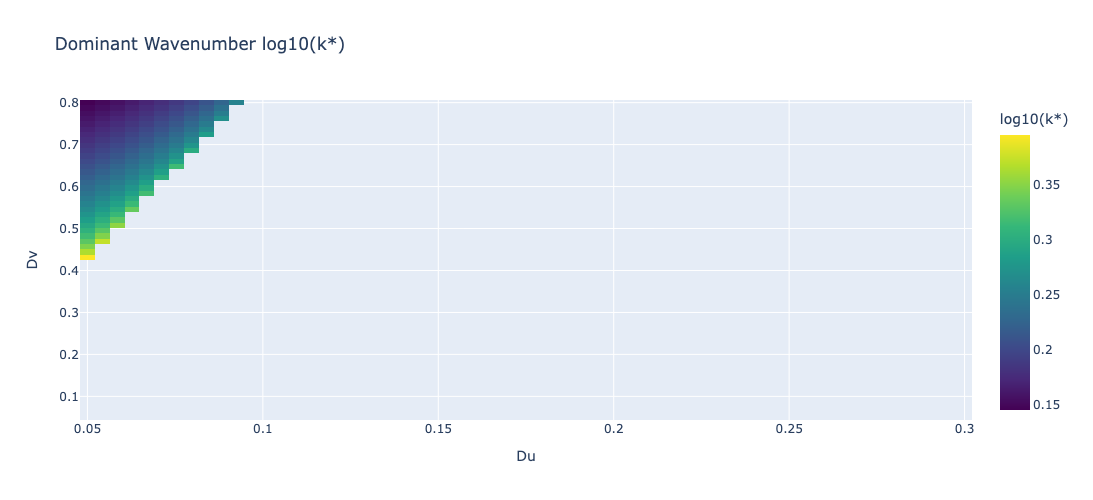

In [9]:
import numpy as np
import plotly.express as px

# Parameters (match your simulation)
a, b = 0.1, 0.9
Du_vals = np.linspace(0.05, 0.30, 60)
Dv_vals = np.linspace(0.05, 0.80, 60)

# Uniform steady state
u0 = a + b
v0 = b / (a + b)**2

# Reaction Jacobian
fu = -1 + 2*u0*v0
fv = u0**2
gu = -2*u0*v0
gv = -u0**2

# Storage for results
unstable = np.zeros((len(Du_vals), len(Dv_vals)), dtype=bool)
k_star = np.full((len(Du_vals), len(Dv_vals)), np.nan)

for i, Du in enumerate(Du_vals):
    for j, Dv in enumerate(Dv_vals):
        A = fu + gv
        B = fu*gv - fv*gu
        # dispersion relation λ(k): λ^2 - λ(A - k^2(Du+Dv)) + B - k^2(Du*gv + Dv*fu) + Du*Dv*k^4 = 0
        # We find k that maximizes Re(λ)
        # For two-variable RD systems, Turing region condition (Murray 2003):
        T1 = Du*gv + Dv*fu
        T2 = T1**2 - 4*Du*Dv*B
        if A < 0 and B > 0 and T1 > 0 and T2 > 0:
            unstable[i, j] = True
            # optimal k^2 for max growth (analytical)
            k2 = (T1 - np.sqrt(T2)) / (2*Du*Dv)
            k_star[i, j] = np.sqrt(max(k2, 0))

# Visualization
fig = px.imshow(
    unstable.T,
    x=Du_vals, y=Dv_vals,
    origin='lower',
    color_continuous_scale=['white', 'red'],
    aspect='auto',
    labels=dict(x='Du', y='Dv', color='Turing unstable'),
    title='Predicted Turing Instability Region (Schnakenberg)'
)
fig.update_layout(width=600, height=500)
fig.show()

fig2 = px.imshow(
    np.log10(k_star.T),
    x=Du_vals, y=Dv_vals,
    origin='lower',
    color_continuous_scale='Viridis',
    aspect='auto',
    labels=dict(x='Du', y='Dv', color='log10(k*)'),
    title='Dominant Wavenumber log10(k*)'
)
fig2.update_layout(width=600, height=500)
fig2.show()


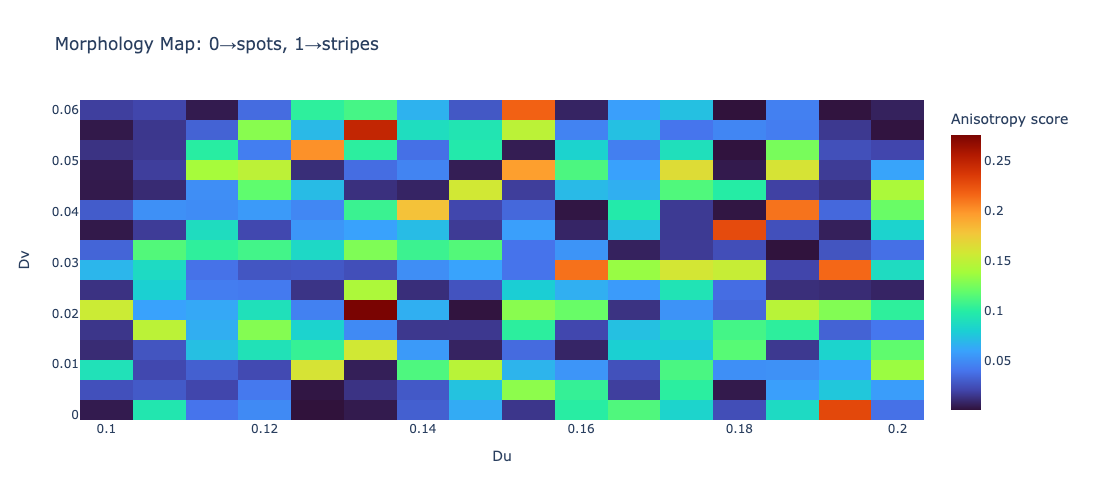

In [10]:
import numpy as np
import plotly.express as px

def morphology_score(field):
    F = np.fft.fftshift(np.fft.fft2(field - field.mean()))
    P = np.abs(F)
    ny, nx = field.shape
    y = np.linspace(-1, 1, ny, endpoint=False)
    x = np.linspace(-1, 1, nx, endpoint=False)
    X, Y = np.meshgrid(x, y)
    theta = np.mod(np.arctan2(Y, X), np.pi)
    eps = 0.15*np.pi
    p0  = P[(theta < eps) | (theta > np.pi - eps)].sum()
    p90 = P[(np.abs(theta - 0.5*np.pi) < eps)].sum()
    return (max(p0, p90) - min(p0, p90)) / (p0 + p90 + 1e-9)

# Compute morphology map
morph_map = np.zeros((patterns_sch.shape[0], patterns_sch.shape[1]))
for i in range(patterns_sch.shape[0]):
    for j in range(patterns_sch.shape[1]):
        morph_map[i, j] = morphology_score(patterns_sch[i, j])

# Normalize and display
fig = px.imshow(
    morph_map.T,
    x=Du_values, y=Dv_values,
    origin='lower',
    color_continuous_scale='Turbo',
    aspect='auto',
    labels=dict(x='Du', y='Dv', color='Anisotropy score'),
    title='Morphology Map: 0→spots, 1→stripes'
)
fig.update_layout(width=600, height=500)
fig.show()
